# Theoretical Analysis of the Bias-Variance Tradeoff in Regression Models

Submitted by: <b>Lanuzo, Jessica Mae T. | BSCS-2A </b>
***
 The bias-variance tradeoff is a basic principle of machine learning that has a
 significant impact on the ability of a model to generalize new data. This study
 explores the bias-variance tradeoff by analyzing various regression models of
 increasing complexity, including linear regression and polynomial regression techniques. A combination of
 theoretical analysis and empirical experimentation will be conducted to demonstrate
 how model complexity influences bias, variance, and the risk of overfitting. Using
 synthetic datasets with varying levels of complexity, the study evaluates model
 performance through mean squared error (MSE), R2 score, and K-fold cross-validation. This
 research aims to offer a deeper understanding of the bias-variance tradeoff, guiding
 practitioners in building regression models that balance simplicity and flexibility for optimal
 generalization.



     The Datasets
 >   The analysis will use synthetic datasets generated using NumPy’s random function. 
 The datasets consist of 10,000 samples, having one feature and one target for each. 
 Moreover, the dataset generation implemented a noise level of 20% to simulate real-world dataset
 imperfections and a normal distribution for the feature value generation.

Notebook Sections:
- Importing the Libraries
- Preparing the Datasets
- Implementing the experiment
    - *Functions reused*

    1. Linear Regression
    1. Polynomial Regression (Degree 2)
    1. Polynomial Regression (Degree 5)
    1. Polynomial Regression (Degree 10)



***

### I. Importing the Libraries

In [1]:
# For data reading, visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# For data preprocessing
from sklearn.model_selection import train_test_split

# For creating the models
from sklearn.linear_model import LinearRegression
    # polynomial regression
from sklearn.preprocessing import PolynomialFeatures 
from sklearn.pipeline import make_pipeline

# For model evaluation
from sklearn import metrics
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score



### II. Preparing the Datasets


 Variations of the synthetic
 dataset were generated to analyze how the bias of models of varying complexity and
 its variance behaves in different learning scenarios, which in this study would be when data relationships
 are simple (linear, of degree 1), increasing in complexity (polynomial, of degrees 2 and 5), and
 complex (polynomial, of degree 10).  These dataset variations were easily generated with the use of NumPy’s random seed assignment and
 by modifying the polynomial degree in the generation process. The polynomial degrees used are as follows, with the coefficients for Dataset 4 decreased to prevent extreme values:

#### > Loading and Labeling the Data

**Dataset 1: y = 3x+ϵ**


In [2]:
dataset1 = pd.read_csv('degree1_dataset.csv')

# Declaring feature and target columns as X and y
X1 = dataset1['x']
y1 = dataset1['y']

**Dataset 2: y = −2x2 +3x+ϵ**

In [3]:
dataset2 = pd.read_csv('degree2_dataset.csv')

# Declaring feature and target columns as X and y
X2 = dataset2['x']
y2 = dataset2['y']

**Dataset 3: y = 5x5 −3x3 +2x+ϵ**

In [4]:
dataset3 = pd.read_csv('degree5_dataset.csv')

# Declaring feature and target columns as X and y
X3 = dataset3['x']
y3 = dataset3['y']

**Dataset 4: y = 0.1X10 −0.5x5 +0.3x3 −0.2x+ϵ**

In [5]:
dataset4 = pd.read_csv('degree10_dataset.csv')

# Declaring feature and target columns as X and y
X4 = dataset4['x']
y4 = dataset4['y']

#### > Plotting the Data

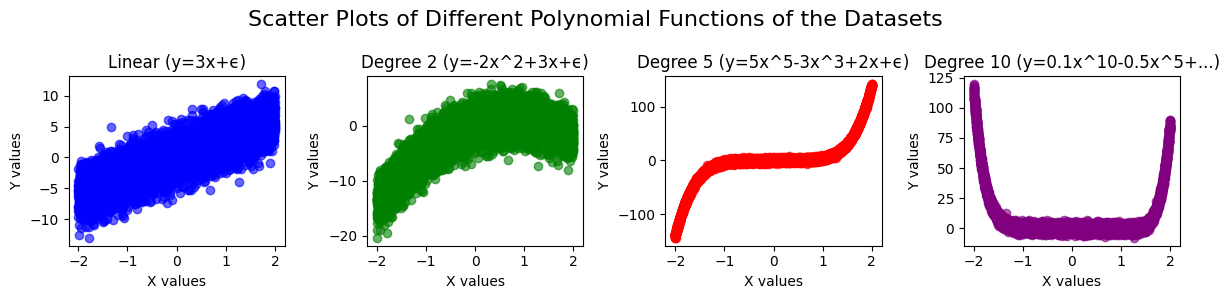

In [6]:
# Creating figure and set of subplots
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
fig.suptitle("Scatter Plots of Different Polynomial Functions of the Datasets", fontsize=16)

# subplot titles
titles = ["Linear (y=3x+ϵ)", "Degree 2 (y=-2x^2+3x+ϵ)", "Degree 5 (y=5x^5-3x^3+2x+ϵ)", "Degree 10 (y=0.1x^10-0.5x^5+...)"]

# Plotting each dataset's X and y
axes[0].scatter(X1, y1, color="blue", alpha=0.6)
axes[1].scatter(X2, y2, color="green", alpha=0.6)
axes[2].scatter(X3, y3, color="red", alpha=0.6)
axes[3].scatter(X4, y4, color="purple", alpha=0.6)

# Titles and labels
for i in range(4):
    axes[i].set_title(titles[i])
    axes[i].set_xlabel("X values")
    axes[i].set_ylabel("Y values")

# Adjusting layout for better appearance
plt.tight_layout()
plt.show()

#### > Splitting Data into Training and Testing Sets

In [7]:
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size = .20, random_state = 1)
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size = .20, random_state = 1)
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size = .20, random_state = 1)
X4_train, X4_test, y4_train, y4_test = train_test_split(X4, y4, test_size = .20, random_state = 1)

In [8]:
# Grouping data subsets
Xtraining_set = [X1_train, X2_train, X3_train, X4_train]
Xtesting_set = [X1_test, X2_test, X3_test, X4_test]
ytraining_set = [y1_train, y2_train, y3_train, y4_train]
ytesting_set = [y1_test, y2_test, y3_test, y4_test]


### III. Training Different Regression Models on each Dataset

#### > Functions reused across models

Function for model training and evaluation; returns dictionary of metrics and test predictions


In [9]:
def evaluate_model(model, Xtrain, ytrain, Xtest, ytest, cv=5):
    # Training model on training sets
    model.fit(Xtrain, ytrain)
    
    # Predicting on training and testing sets
    y_train_pred = model.predict(Xtrain)
    y_test_pred = model.predict(Xtest)
    
    # Computing train and test MSE
    train_mse = mean_squared_error(ytrain, y_train_pred)
    test_mse = mean_squared_error(ytest, y_test_pred)
    
    # Computing train and test R2 
    train_r2 = r2_score(ytrain, y_train_pred)
    test_r2 = r2_score(ytest, y_test_pred)
    
    # Cross validation
    cv_scores = cross_val_score(model, Xtrain, ytrain, cv=cv, scoring="neg_mean_squared_error")
    cv_mse = -cv_scores.mean()
    
    return {
        "train_mse": train_mse,
        "test_mse": test_mse,
        "train_r2": train_r2,
        "test_r2": test_r2,
        "cv_mse": cv_mse,
        "y_test_pred": y_test_pred
    }

Function for organizing results into respective lists

In [10]:
def append_results(results, train_mse_results, test_mse_results, cv_results, train_r2_results, test_r2_results, predictions):
    # Organizing results to containers for display later
    train_mse_results.append(results["train_mse"])
    test_mse_results.append(results["test_mse"])
    train_r2_results.append(results["train_r2"])
    test_r2_results.append(results["test_r2"])
    cv_results.append(results["cv_mse"])
    predictions.append(results["y_test_pred"])

Function to print and plot results

In [11]:
def print_and_plot_results(train_mse, test_mse, train_r2, test_r2, cv_mse, X_test, y_test, predictions):
    # Printing metrics
    for i in range(4):
        print(f"Dataset {i+1}: "
              f"Train MSE = {train_mse[i]:.4f}, "
              f"Test MSE = {test_mse[i]:.4f}, "
              f"Train R² = {train_r2[i]:.4f}, "
              f"Test R² = {test_r2[i]:.4f}, "
              f"Cross-Validated MSE = {cv_mse[i]:.4f}")

    # Plotting results
    fig, axes = plt.subplots(1, 4, figsize=(12, 3))
    fig.suptitle("Linear (Degree 1) Regression on Synthetic Datasets", fontsize=16)

    dataset_titles = ["Dataset 1", "Dataset 2", "Dataset 3", "Dataset 4"]

    for i, ax in enumerate(axes):
        ax.scatter(X_test[i], y_test[i], color="blue", alpha=0.5, label="True Values")
        ax.scatter(X_test[i], predictions[i], color="red", alpha=0.5, label="Predictions")
        ax.set_title(dataset_titles[i])
        ax.set_xlabel("Feature X")
        ax.set_ylabel("Target Y")
        ax.legend()
        ax.set_xticks([])
        ax.set_yticks([])

    plt.tight_layout()
    plt.show()

#### > Linear Regression Model

Dataset 1: Train MSE = 3.9945, Test MSE = 4.0088, Train R² = 0.7469, Test R² = 0.7435, Cross-Validated MSE = 3.9967
Dataset 2: Train MSE = 9.7643, Test MSE = 9.4694, Train R² = 0.5527, Test R² = 0.5579, Cross-Validated MSE = 9.7705
Dataset 3: Train MSE = 575.8171, Test MSE = 531.8750, Train R² = 0.6606, Test R² = 0.6657, Cross-Validated MSE = 575.9762
Dataset 4: Train MSE = 418.1519, Test MSE = 364.7743, Train R² = 0.0315, Test R² = 0.0283, Cross-Validated MSE = 418.2896


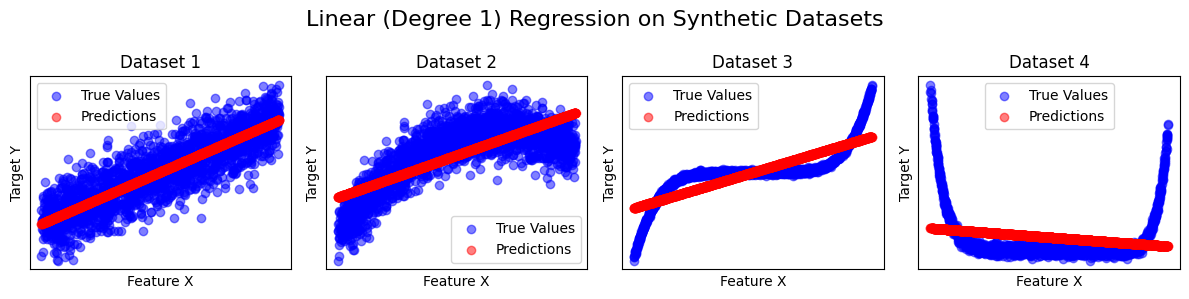

In [12]:
# Container for MSEs, R² scores, and predictions
train1_mse_results = []
test1_mse_results = []
cv1_results = []
train1_r2_results = []
test1_r2_results = []
predictions1 = []

# Training Loop for each Dataset
for Xtrain, ytrain, Xtest, ytest in zip(Xtraining_set, ytraining_set, Xtesting_set, ytesting_set):
    
    model = LinearRegression() # choosing the model
    
    # Model training and computation of metrics
    results = evaluate_model(model, Xtrain.values.reshape(-1, 1), ytrain,
                             Xtest.values.reshape(-1, 1), ytest)
    
    # Organizing results to containers for display later
    append_results(results, train1_mse_results, test1_mse_results, cv1_results, train1_r2_results, test1_r2_results, predictions1)

# Displaying results
print_and_plot_results(train1_mse_results, test1_mse_results, train1_r2_results, test1_r2_results, cv1_results, Xtesting_set, ytesting_set, predictions1)


#### > Polynomial Regression Model (Degree 2)

Dataset 1: Train MSE = 3.9943, Test MSE = 4.0095, Train R² = 0.7470, Test R² = 0.7435, Cross-Validated MSE = 3.9982
Dataset 2: Train MSE = 3.9943, Test MSE = 4.0095, Train R² = 0.8170, Test R² = 0.8128, Cross-Validated MSE = 3.9982
Dataset 3: Train MSE = 575.5476, Test MSE = 532.2921, Train R² = 0.6607, Test R² = 0.6655, Cross-Validated MSE = 575.7392
Dataset 4: Train MSE = 163.8438, Test MSE = 149.6909, Train R² = 0.6205, Test R² = 0.6012, Cross-Validated MSE = 163.9589


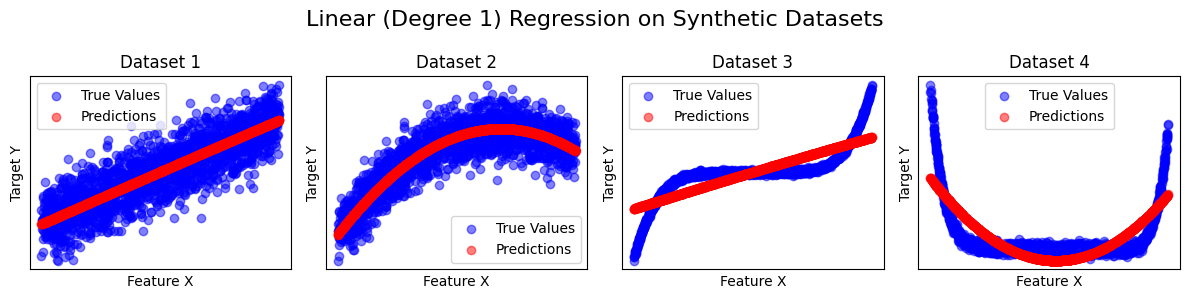

In [13]:
# Container for MSEs, cross-validation results, and predictions
test2_mse_results = []
cv2_results = []
train2_mse_results = []
train2_r2_results = []
test2_r2_results = []
predictions2 = []

# Train, evaluate, and predict model across datasets
for Xtrain, ytrain, Xtest, ytest in zip(Xtraining_set, ytraining_set, Xtesting_set, ytesting_set):
    # Creating polynomial regression model pipeline
    poly_model = make_pipeline(PolynomialFeatures(2), LinearRegression())
    
    # Model training and computation of metrics
    results = evaluate_model(poly_model, Xtrain.values.reshape(-1, 1), ytrain,
                             Xtest.values.reshape(-1, 1), ytest)
    
    # Organizing results to containers for display later
    append_results(results, train2_mse_results, test2_mse_results, cv2_results, train2_r2_results, test2_r2_results, predictions2)

# Displaying results
print_and_plot_results(train2_mse_results, test2_mse_results, train2_r2_results, test2_r2_results, cv2_results, Xtesting_set, ytesting_set, predictions2)



#### > Polynomial Regression Model (Degree 5)

Dataset 1: Train MSE = 3.9918, Test MSE = 4.0091, Train R² = 0.7471, Test R² = 0.7435, Cross-Validated MSE = 3.9971
Dataset 2: Train MSE = 3.9918, Test MSE = 4.0091, Train R² = 0.8172, Test R² = 0.8128, Cross-Validated MSE = 3.9971
Dataset 3: Train MSE = 3.9918, Test MSE = 4.0091, Train R² = 0.9976, Test R² = 0.9975, Cross-Validated MSE = 3.9971
Dataset 4: Train MSE = 28.5725, Test MSE = 28.0748, Train R² = 0.9338, Test R² = 0.9252, Cross-Validated MSE = 28.6551


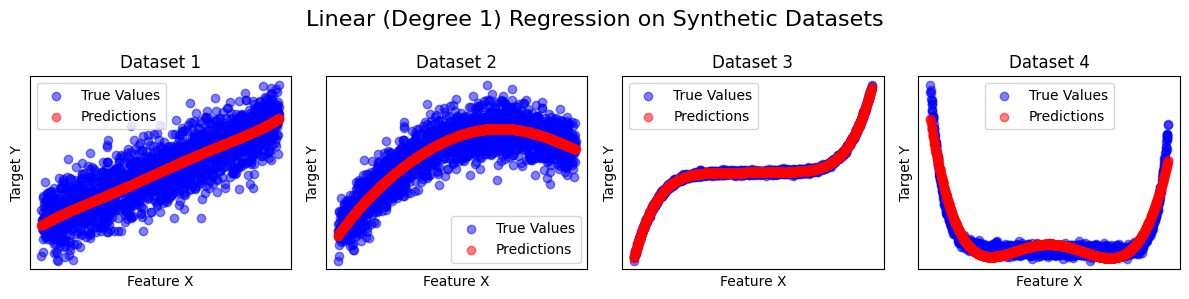

In [14]:
# Container for MSEs, cross-validation results, and predictions
test5_mse_results = []
cv5_results = []
train5_mse_results = []
train5_r2_results = []
test5_r2_results = []
predictions5 = []

# Train, evaluate, and predict model across datasets
for Xtrain, ytrain, Xtest, ytest in zip(Xtraining_set, ytraining_set, Xtesting_set, ytesting_set):
    # Create polynomial regression model pipeline
    poly_model = make_pipeline(PolynomialFeatures(5), LinearRegression())
    
    # Model training and computation of metrics
    results = evaluate_model(poly_model, Xtrain.values.reshape(-1, 1), ytrain,
                             Xtest.values.reshape(-1, 1), ytest)
    
    # Organizing results to containers for display later
    append_results(results, train5_mse_results, test5_mse_results, cv5_results, train5_r2_results, test5_r2_results, predictions5)

# Displaying results
print_and_plot_results(train5_mse_results, test5_mse_results, train5_r2_results, test5_r2_results, cv5_results, Xtesting_set, ytesting_set, predictions5)

#### > Polynomial Regression Model (Degree 10)

Dataset 1: Train MSE = 3.9898, Test MSE = 4.0093, Train R² = 0.7472, Test R² = 0.7435, Cross-Validated MSE = 4.0049
Dataset 2: Train MSE = 3.9898, Test MSE = 4.0093, Train R² = 0.8172, Test R² = 0.8128, Cross-Validated MSE = 4.0049
Dataset 3: Train MSE = 3.9898, Test MSE = 4.0093, Train R² = 0.9976, Test R² = 0.9975, Cross-Validated MSE = 4.0049
Dataset 4: Train MSE = 3.9898, Test MSE = 4.0093, Train R² = 0.9908, Test R² = 0.9893, Cross-Validated MSE = 4.0049


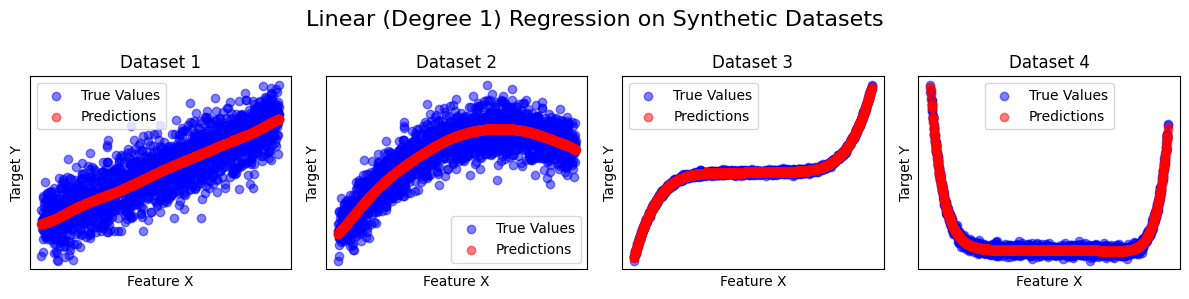

In [15]:
# Container for MSEs, cross-validation results, and predictions
testX_mse_results = []
cvX_results = []
trainX_mse_results = []
trainX_r2_results = []
testX_r2_results = []
predictionsX = []

# Train, evaluate, and predict model across datasets
for Xtrain, ytrain, Xtest, ytest in zip(Xtraining_set, ytraining_set, Xtesting_set, ytesting_set):
    # Create polynomial regression model pipeline
    poly_model = make_pipeline(PolynomialFeatures(10), LinearRegression())
    
    # Model training and computation of metrics
    results = evaluate_model(poly_model, Xtrain.values.reshape(-1, 1), ytrain,
                             Xtest.values.reshape(-1, 1), ytest)
    
        # Organizing results to containers for display later
    append_results(results, trainX_mse_results, testX_mse_results, cvX_results, trainX_r2_results, testX_r2_results, predictionsX)

# Displaying results
print_and_plot_results(trainX_mse_results, testX_mse_results, trainX_r2_results, testX_r2_results, cvX_results, Xtesting_set, ytesting_set, predictionsX)